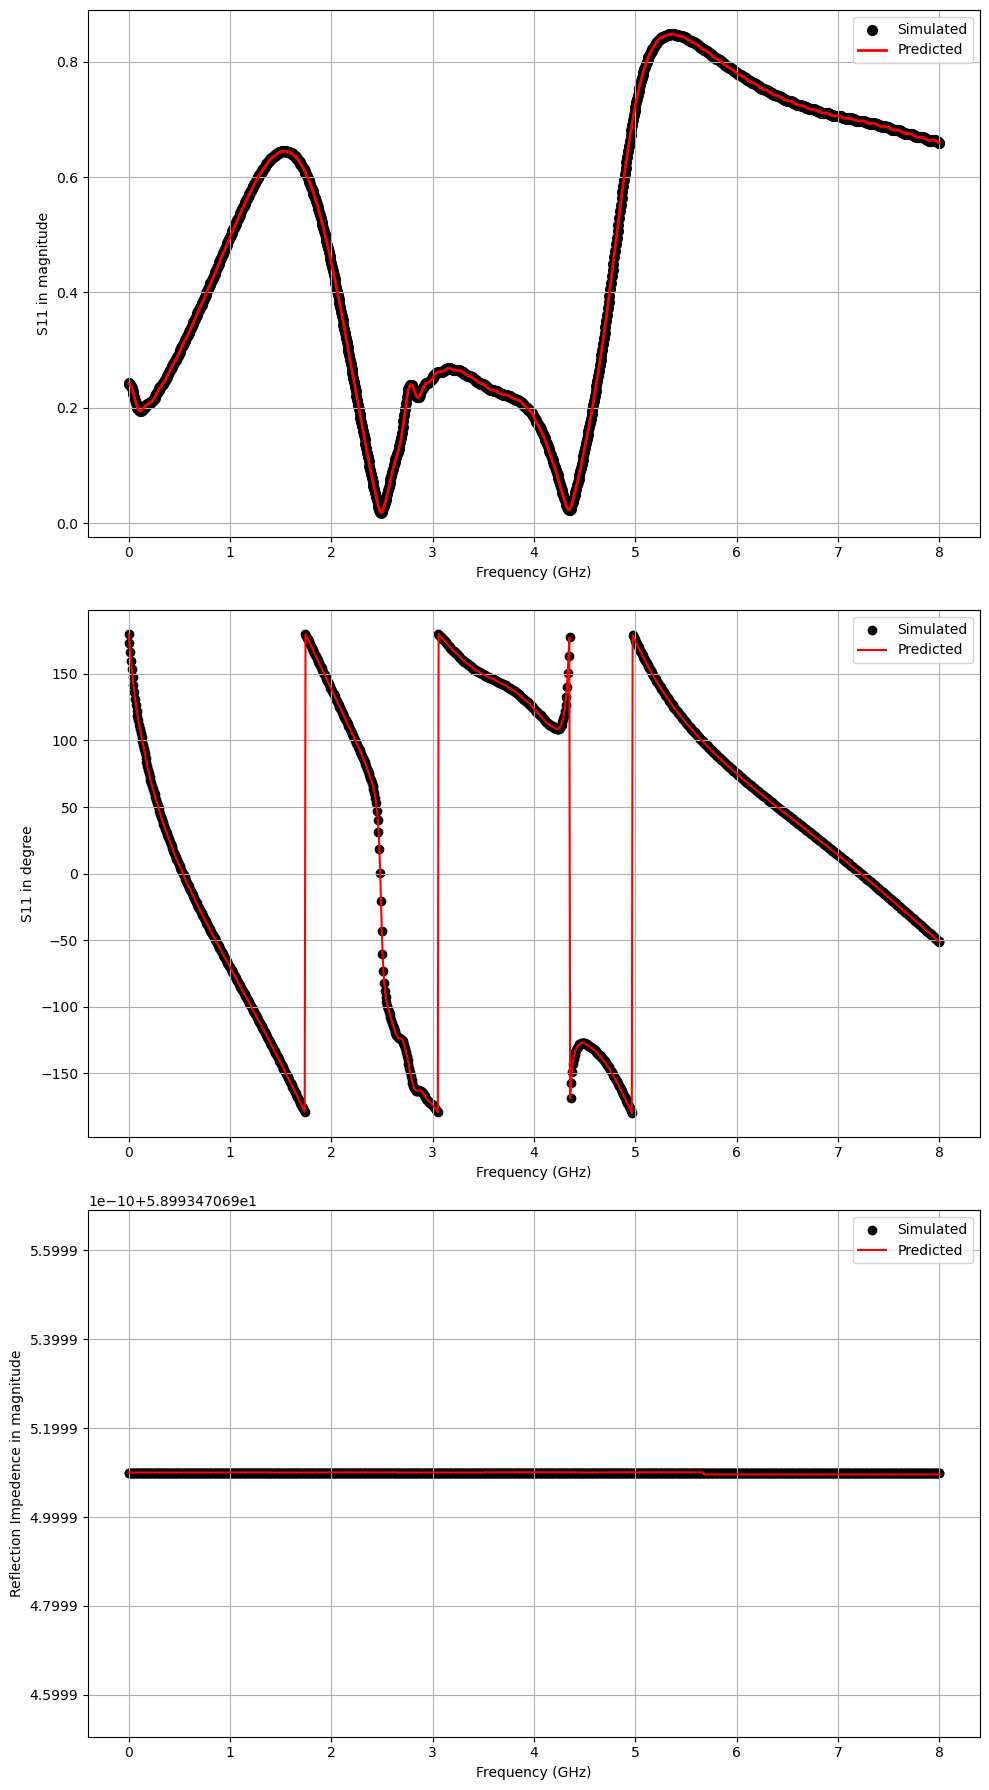

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.tree import DecisionTreeRegressor
import re
import warnings
warnings.filterwarnings('ignore')

# 1. Load and clean the dataset
df = pd.read_csv('s11.csv')
df = df.dropna(axis=1, how='all')

# 2. Define features and prediction range
X = df[['Frequency_in_GHz']]
X_test = np.linspace(X.min(), X.max(), 1000).reshape(-1, 1)

# 3. Initialize the figure with 3 subplots
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# --- TARGET 1: S11_in_mag ---
y1 = df['S11_in_mag']
dt1 = DecisionTreeRegressor(random_state=42)
dt1.fit(X, y1)
y_pred1 = dt1.predict(X_test)

axes[0].scatter(X, y1, color="black",linewidth=2, label='Simulated')
axes[0].plot(X_test, y_pred1, color="red", label='Predicted', linewidth=2)
axes[0].set_xlabel('Frequency (GHz)')
axes[0].set_ylabel('S11 in magnitude')
axes[0].legend()
axes[0].grid(True)

# --- TARGET 2: S11_in_deg ---
y2 = df['S11_in_deg']
dt2 = DecisionTreeRegressor(random_state=42)
dt2.fit(X, y2)
y_pred2 = dt2.predict(X_test)

axes[1].scatter(X, y2, color='black', label='Simulated')
axes[1].plot(X_test, y_pred2, color='red', label='Predicted')
axes[1].set_xlabel('Frequency (GHz)')
axes[1].set_ylabel('S11 in degree')
axes[1].legend()
axes[1].grid(True)

# --- TARGET 3: Ref_Imp_in_mag ---
y3 = df['Ref_Imp_in_mag']
dt3 = DecisionTreeRegressor(random_state=42)
dt3.fit(X, y3)
y_pred3 = dt3.predict(X_test)


axes[2].scatter(X, y3, color='black', label='Simulated')
axes[2].plot(X_test, y_pred3, color='red', label='Predicted')
axes[2].set_xlabel('Frequency (GHz)')
axes[2].set_ylabel('Reflection Impedence in magnitude')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.savefig('decision_tree_plotsss.png')
plt.show()